In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
rfm = pd.read_csv("../data/processed/customer_rfm.csv")

print("RFM dataset loaded!")
print("Customers:", len(rfm))
print("Columns:", len(rfm.columns))

RFM dataset loaded!
Customers: 4312
Columns: 4


In [3]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346.0,164,11,372.86
1,12347.0,2,2,1323.32
2,12348.0,73,1,222.16
3,12349.0,42,3,2671.14
4,12351.0,10,1,300.93


In [4]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
)

In [5]:
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

In [6]:
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

In [7]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346.0,164,11,372.86,2,5,2
1,12347.0,2,2,1323.32,5,2,4
2,12348.0,73,1,222.16,2,1,1
3,12349.0,42,3,2671.14,3,3,5
4,12351.0,10,1,300.93,5,1,2


In [8]:
rfm["R_Score"] = rfm["R_Score"].astype(int)
rfm["F_Score"] = rfm["F_Score"].astype(int)
rfm["M_Score"] = rfm["M_Score"].astype(int)

In [9]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

In [10]:
def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    
    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"
    
    elif row["R_Score"] >= 4 and row["F_Score"] >= 2:
        return "Potential Loyalists"
    
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    
    else:
        return "Needs Attention"

In [11]:
rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

In [12]:
rfm["Customer_Segment"].value_counts()

Customer_Segment
Needs Attention        1702
Champions               926
At Risk                 688
Potential Loyalists     517
Loyal Customers         479
Name: count, dtype: int64

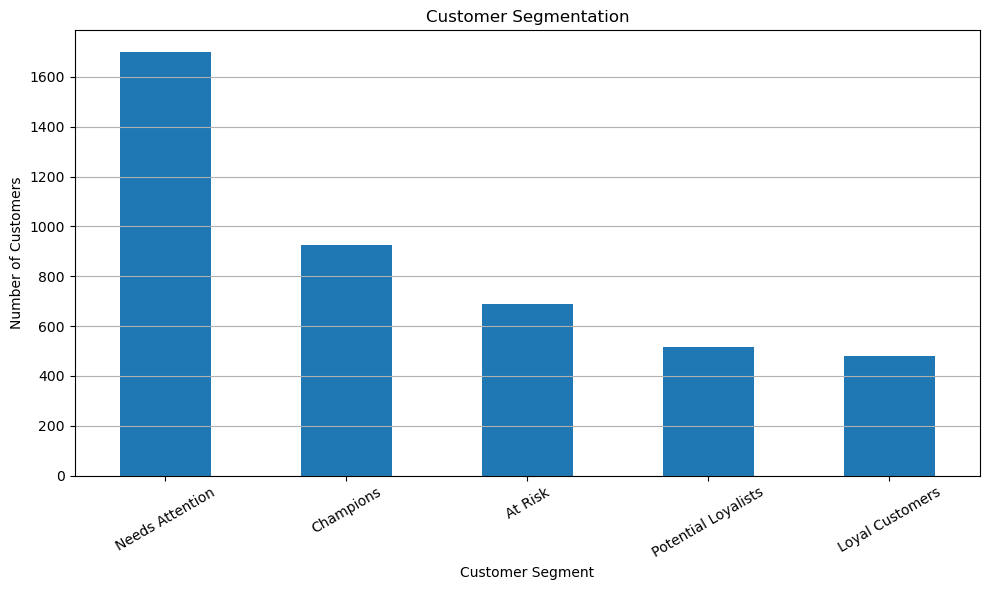

In [13]:
segment_counts = (
    rfm["Customer_Segment"]
    .value_counts()
)

plt.figure(figsize=(10, 6))

segment_counts.plot(kind="bar")

plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig(
    "../charts/customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
segment_revenue = (
    rfm.groupby("Customer_Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

segment_revenue

Customer_Segment
Champions              5712430.697
At Risk                1036709.791
Loyal Customers         845933.702
Needs Attention         828424.704
Potential Loyalists     374734.850
Name: Monetary, dtype: float64

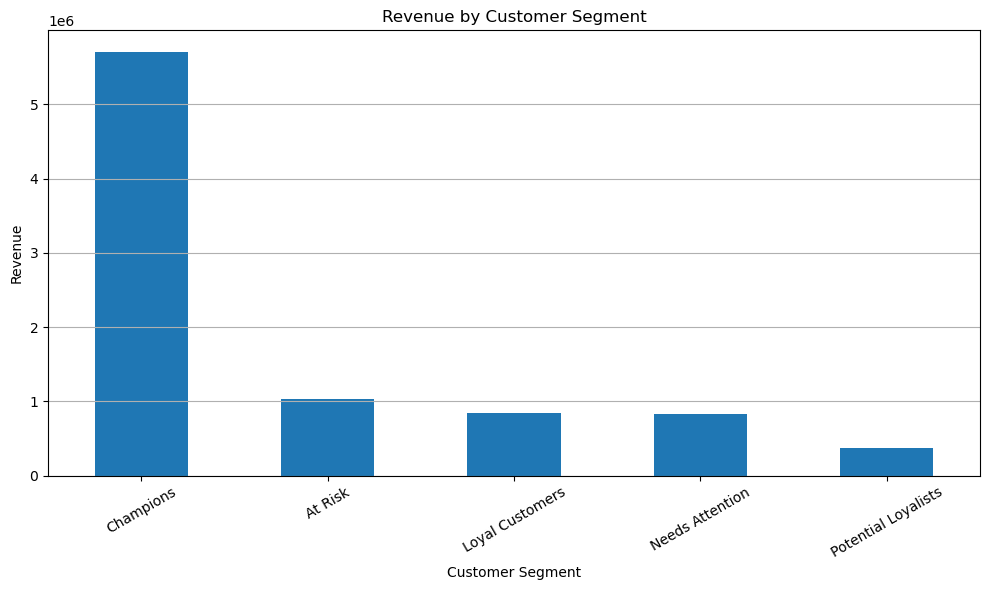

In [15]:
plt.figure(figsize=(10, 6))

segment_revenue.plot(kind="bar")

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig(
    "../charts/revenue_by_customer_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
df = pd.read_csv(
    "../data/processed/cleaned_transactions.csv"
)

In [17]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [18]:
country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

In [19]:
country_revenue.head(10)

Country
United Kingdom    7381644.433
EIRE               356041.860
Netherlands        268784.350
Germany            202025.391
France             146107.070
Sweden              53147.990
Denmark             50906.850
Spain               47568.650
Switzerland         43921.390
Australia           31446.800
Name: Revenue, dtype: float64

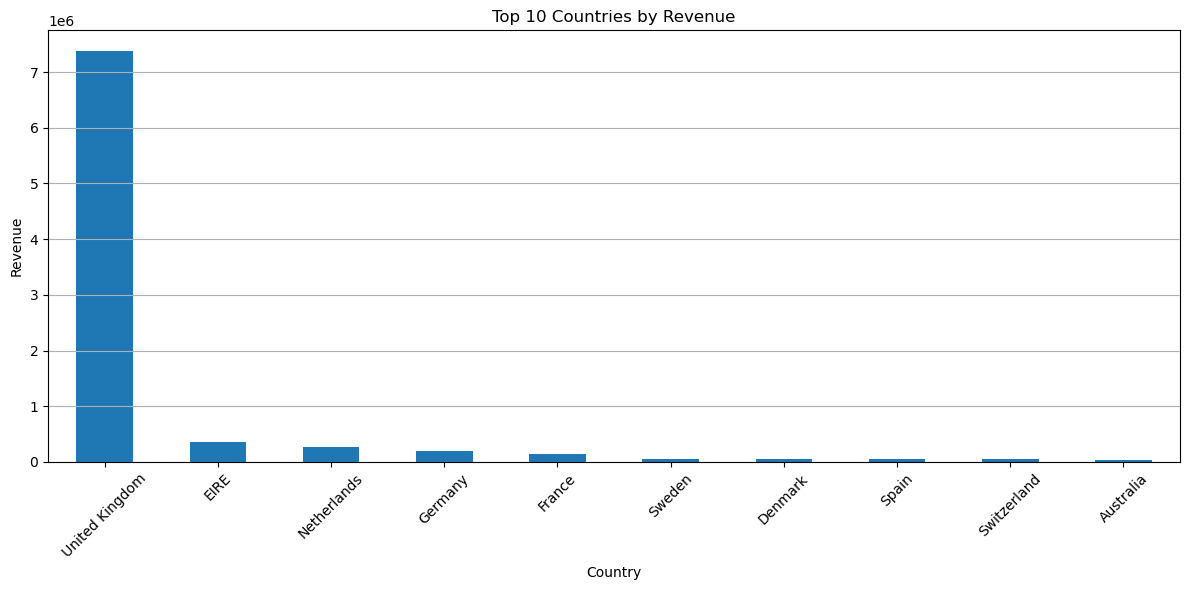

In [20]:
top_countries = country_revenue.head(10)

plt.figure(figsize=(12, 6))

top_countries.plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig(
    "../charts/top_10_countries_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
monthly_revenue = (
    df.set_index("InvoiceDate")
    .resample("ME")["Revenue"]
    .sum()
)

In [22]:
monthly_revenue.head()

InvoiceDate
2009-12-31    683504.010
2010-01-31    555802.672
2010-02-28    504558.956
2010-03-31    696978.471
2010-04-30    591982.002
Freq: ME, Name: Revenue, dtype: float64

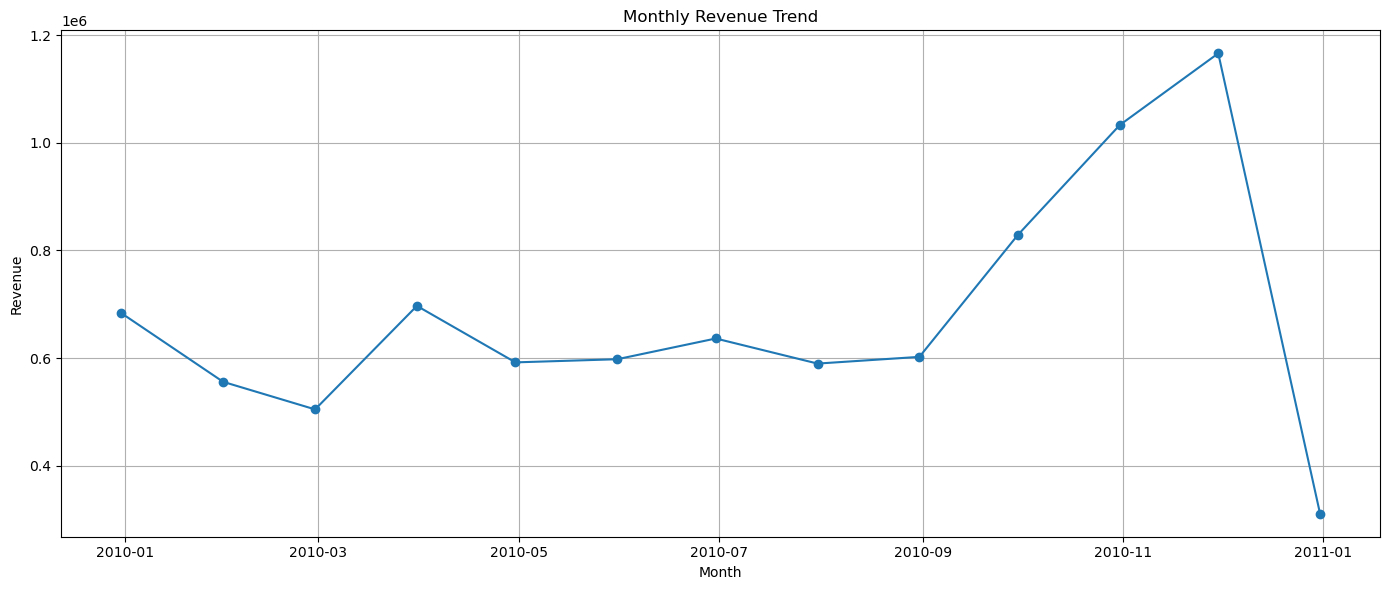

In [23]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../charts/monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
product_revenue = (
    df.groupby(["StockCode", "Description"])["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

In [25]:
top_products = product_revenue.head(10)

top_products

StockCode  Description                        
85123A     WHITE HANGING HEART T-LIGHT HOLDER     151339.16
22423      REGENCY CAKESTAND 3 TIER               143727.60
M          Manual                                  98531.99
84879      ASSORTED COLOUR BIRD ORNAMENT           70291.03
85099B     JUMBO BAG RED RETROSPOT                 51644.25
POST       POSTAGE                                 48741.08
84347      ROTATING SILVER ANGELS T-LIGHT HLDR     40156.05
22086      PAPER CHAIN KIT 50'S CHRISTMAS          36871.55
47566      PARTY BUNTING                           35017.30
15056N     EDWARDIAN PARASOL NATURAL               34044.75
Name: Revenue, dtype: float64

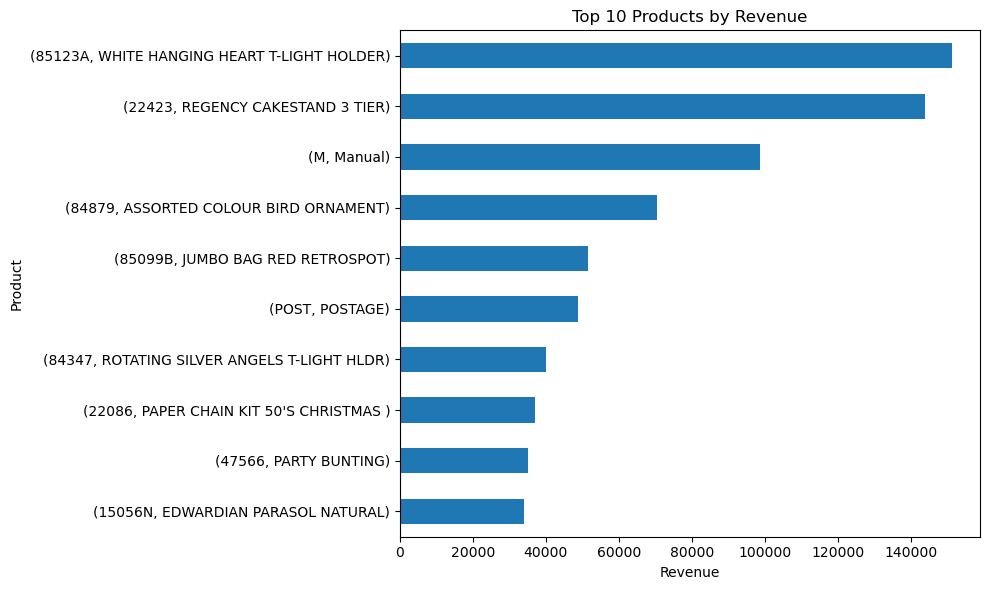

In [26]:
top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "../charts/top_10_products_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

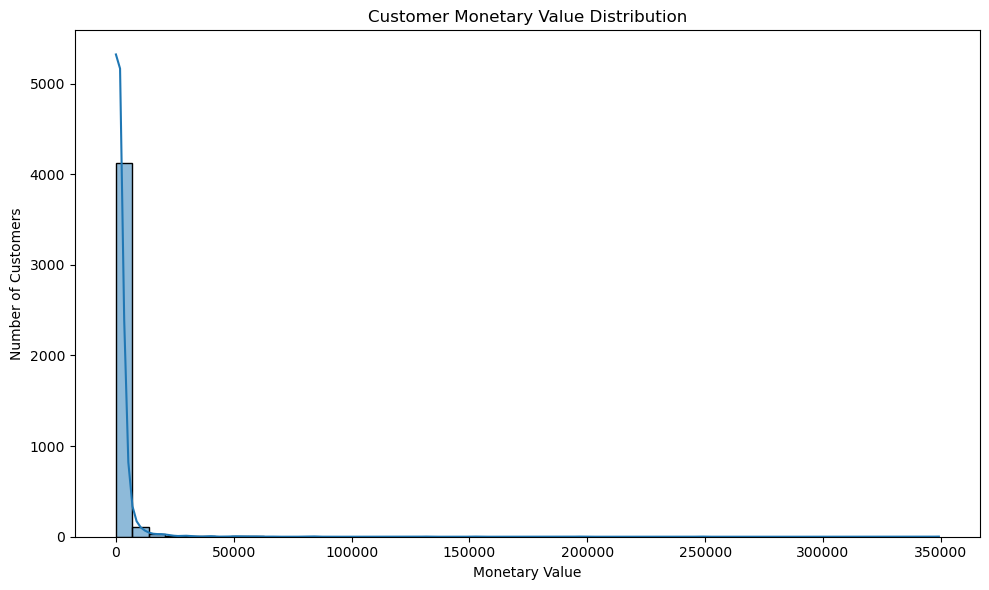

In [27]:
plt.figure(figsize=(10, 6))

sns.histplot(
    rfm["Monetary"],
    bins=50,
    kde=True
)

plt.title("Customer Monetary Value Distribution")
plt.xlabel("Monetary Value")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../charts/monetary_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
rfm.to_csv(
    "../data/processed/customer_rfm_segmented.csv",
    index=False
)

print("Segmented RFM dataset saved successfully!")

Segmented RFM dataset saved successfully!
